In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# 1. Training data (train.csv)

In [1]:
# ---------------------------------------------------------
# 1. Master DataFrame Summary Function
# ---------------------------------------------------------
def summarize_dataframe(df: pd.DataFrame, name: str = "DataFrame") -> pd.DataFrame:
    """Computes high-level overview of DataFrame columns, data types, missing values, and uniqueness."""
    print(f"=== {name} Overview ===")
    print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

    summary = pd.DataFrame(
        {
            "dtype": df.dtypes,
            "non_null_count": df.notnull().sum(),
            "null_count": df.isnull().sum(),
            "null_pct": (df.isnull().sum() / len(df) * 100).round(2),
            "nunique": df.nunique(),
            "min": df.min(),
            "max": df.max(),
        }
    )
    return summary

NameError: name 'pd' is not defined

In [3]:
import pandas as pd
df = pd.read_csv("data_raw/soil_chemistry_2021_raw.csv")

In [6]:
summary_df = summarize_dataframe(df, "Training Data")

=== Training Data Overview ===
Shape: 125,497,040 rows × 6 columns


In [ ]:
import sqlite3

con = sqlite3.connect("myco.db")
joined = pd.read_sql(
    """
    SELECT s.sample_id,
           sub.plant_name,
           sub.particle_size_mm,
           m.compressive_stress_at_10pct_strain_MPa AS stress_10pct_MPa
    FROM sample AS s
    LEFT JOIN substrates AS sub ON s.substrate_id = sub.substrate_id
    LEFT JOIN measurement AS m ON s.sample_id = m.sample_id
    """,
    con,
)
con.close()

# Measurements can have several rows per sample (raw + mean); collapse to one row per sample
samples = joined.groupby("sample_id", as_index=False).agg(
    plant_name=("plant_name", "first"),
    particle_size_mm=("particle_size_mm", "first"),
    stress_10pct_MPa=("stress_10pct_MPa", "mean"),
)
print(f"Samples: {len(samples)}")

# Use the same plant_name colour assignment as the previous plot
stress_df = samples.dropna(subset=["stress_10pct_MPa"])
plant_colour_order = stress_df["plant_name"].unique().tolist()

# Plot: compressive stress at 10% strain vs substrate particle size, coloured by plant_name
plot_df = samples.dropna(subset=["particle_size_mm", "stress_10pct_MPa"])
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=plot_df,
    x="particle_size_mm",
    y="stress_10pct_MPa",
    hue="plant_name",
    hue_order=plant_colour_order,
    s=60,
    alpha=0.8,
)
plt.xscale("log")
plt.title(
    f"Compressive Stress at 10% Strain vs Substrate Particle Size (n={len(plot_df)} samples)"
)
plt.xlabel("Particle Size (mm, log scale)")
plt.ylabel("Compressive Stress at 10% Strain (MPa)")
plt.legend(title="Plant Name", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [50]:
df.tail()

,id,date,store_nbr,item_nbr,unit_sales,onpromotion
125497035,125497035,2017-08-15,54,2089339,4.0,False
125497036,125497036,2017-08-15,54,2106464,1.0,True
125497037,125497037,2017-08-15,54,2110456,192.0,False
125497038,125497038,2017-08-15,54,2113914,198.0,True
125497039,125497039,2017-08-15,54,2116416,2.0,False


Check on-promotion missing dates

In [5]:
df[df["onpromotion"].isna()].min()

id                               0
date           2013-01-01 00:00:00
store_nbr                        1
item_nbr                     96995
unit_sales                 -1344.0
onpromotion                   <NA>
dtype: object

In [6]:
df[df["onpromotion"].isna()].max()

id                        21657650
date           2014-03-31 00:00:00
store_nbr                       54
item_nbr                   1909755
unit_sales                 12021.0
onpromotion                   <NA>
dtype: object

Check sale each year

In [ ]:
def plot_store_items_time_series(
    df, store_id=1, item_ids=None, start_date="2016-01-01", end_date="2016-06-30"
):
    """Plots daily unit sales for specific items in a given store."""
    if item_ids is None:
        item_ids = df.groupby("item_nbr")["unit_sales"].sum().nlargest(5).index.tolist()

    # Filter data fast
    mask = (
        (df["date"] >= start_date)
        & (df["date"] <= end_date)
        & (df["store_nbr"] == store_id)
        & (df["item_nbr"].isin(item_ids))
    )
    sub_df = df[mask]

    plt.figure(figsize=(14, 5))
    sns.scatterplot(
        data=sub_df, x="date", y="unit_sales", hue="item_nbr", palette="tab10", lw=1.5
    )

    plt.title(f"Daily Unit Sales for Store {store_id} ({start_date} to {end_date})")
    plt.xlabel("Date")
    plt.ylabel("Unit Sales")
    plt.legend(title="Item Number")
    plt.tight_layout()
    plt.show()

In [ ]:
# Top 5 best-selling / most frequent items
top_5_items = df["item_nbr"].value_counts().head(5).index.tolist()

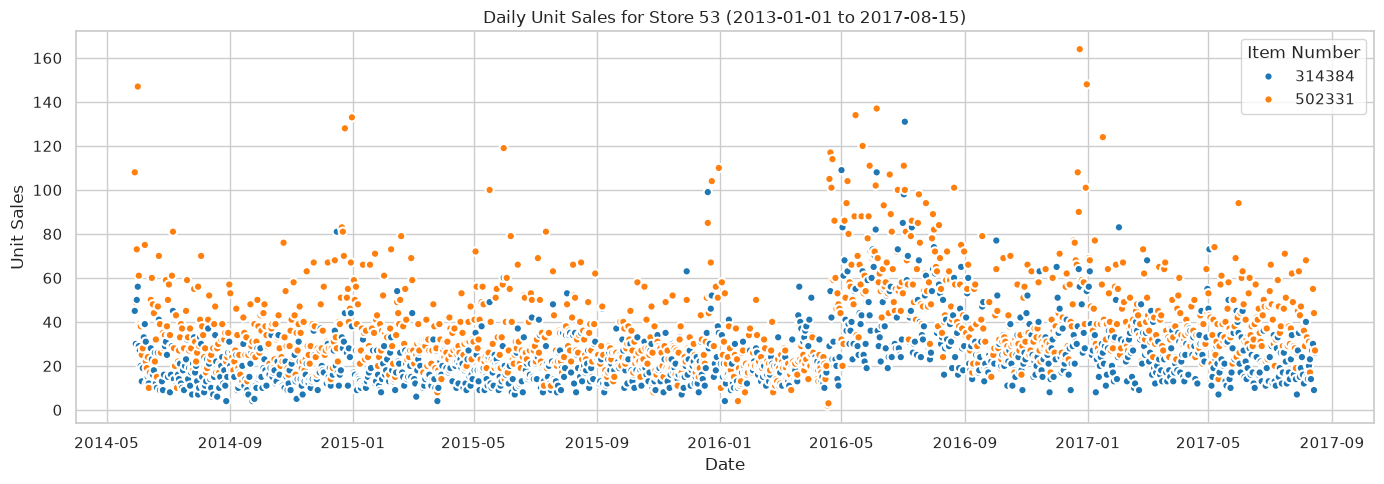

In [ ]:
plot_store_items_time_series(
    df,
    store_id=53,
    item_ids=top_5_items[0:2],
    start_date="2013-01-01",
    end_date="2017-08-15",
)

In [ ]:
def plot_daily_sales_by_stores(
    df, store_ids=[1, 2, 3, 44, 45], start_date="2016-01-01", end_date="2016-06-30"
):
    """
    Filters data by date range and store list, computes total daily unit sales
    per store, and plots total sales over time.
    """
    # 1. Filter data fast
    mask = (
        (df["date"] >= start_date)
        & (df["date"] <= end_date)
        & (df["store_nbr"].isin(store_ids))
    )
    df_filtered = df[mask]

    # 2. Aggregate total daily sales per store
    daily_sales = (
        df_filtered.groupby(["date", "store_nbr"])["unit_sales"].sum().reset_index()
    )

    # 3. Plot line chart
    plt.figure(figsize=(15, 6))
    sns.lineplot(
        data=daily_sales,
        x="date",
        y="unit_sales",
        hue="store_nbr",
        palette="tab10",
        linewidth=1.5,
    )

    plt.title(
        f"Total Daily Unit Sales for Selected Stores ({start_date} to {end_date})",
        fontsize=14,
    )
    plt.xlabel("Date", fontsize=12)
    plt.ylabel("Total Unit Sales", fontsize=12)
    plt.legend(title="Store Number", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

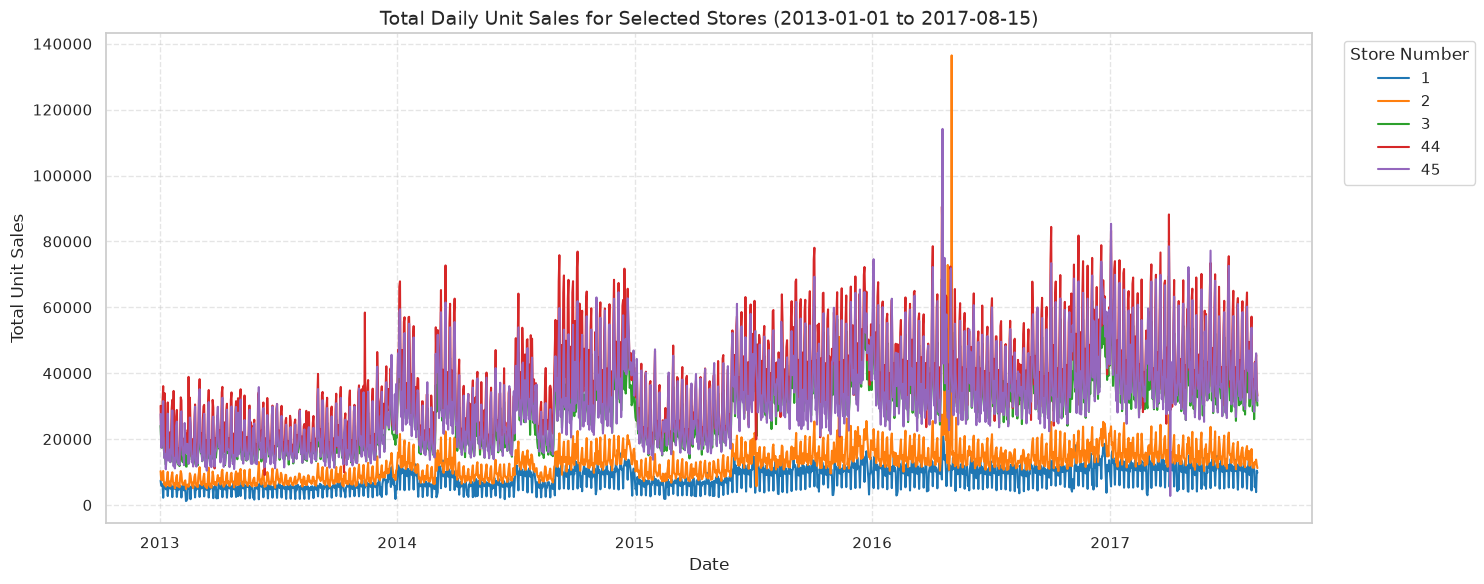

In [ ]:
# Plot total daily sales for stores 1, 2, 3, 44, 45 across the first half of 2016
plot_daily_sales_by_stores(
    df, store_ids=[1, 2, 3, 44, 45], start_date="2013-01-01", end_date="2017-08-15"
)

# 2. transactions.csv

In [ ]:
df = pd.read_parquet(
    "../data/favorita-grocery-sales-forecasting/cleaned/transactions_clean.parquet"
)

In [75]:
summary_df = summarize_dataframe(df, "Transactions Data")

=== Transactions Data Overview ===
Shape: 83,488 rows × 3 columns


In [76]:
summary_df

,dtype,non_null_count,null_count,null_pct,nunique,min,max
date,datetime64[us],83488,0,0.0,1682,2013-01-01 00:00:00,2017-08-15 00:00:00
store_nbr,int64,83488,0,0.0,54,1,54
transactions,int64,83488,0,0.0,4993,5,8359


In [74]:
df.head()

,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


# Store data stores.csv

In [ ]:
df = pd.read_parquet(
    "../data/favorita-grocery-sales-forecasting/cleaned/stores_clean.parquet"
)

In [80]:
summary_df = summarize_dataframe(df, "Stores Data")

=== Stores Data Overview ===
Shape: 54 rows × 5 columns


In [81]:
summary_df

,dtype,non_null_count,null_count,null_pct,nunique,min,max
store_nbr,int64,54,0,0.0,54,1,54
city,str,54,0,0.0,22,Ambato,Santo Domingo
state,str,54,0,0.0,16,Azuay,Tungurahua
type,str,54,0,0.0,5,A,E
cluster,int64,54,0,0.0,17,1,17


Number of stores in each cluster

In [ ]:
num_stores_per_cluster = df.groupby(["cluster"])["store_nbr"].count()

<Axes: xlabel='cluster', ylabel='store_nbr'>

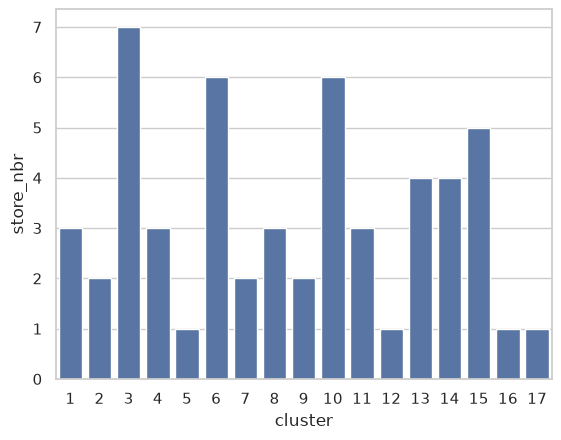

In [86]:
sns.barplot(num_stores_per_cluster)

Number of stores in each type

<Axes: xlabel='type', ylabel='store_nbr'>

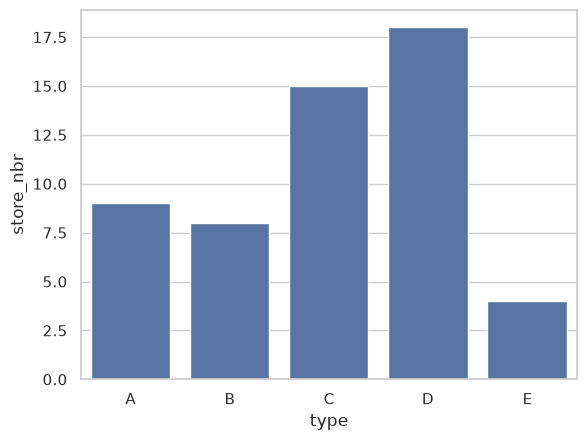

In [ ]:
num_stores_per_type = df.groupby(["type"])["store_nbr"].count()
sns.barplot(num_stores_per_type)

No. of stores in each state

<Axes: xlabel='store_count', ylabel='state'>

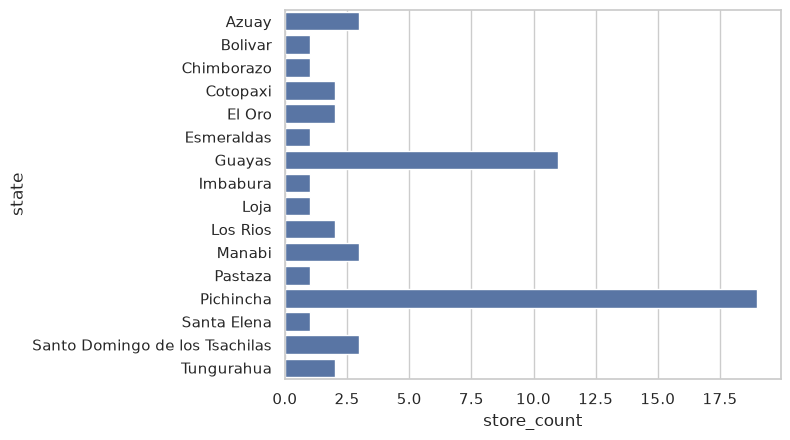

In [ ]:
num_stores_per_state = (
    df.groupby(["state"])["store_nbr"].count().reset_index(name="store_count")
)
sns.barplot(
    num_stores_per_state,
    y=num_stores_per_state["state"],
    x=num_stores_per_state["store_count"],
)

No. of stores in each city

<Axes: xlabel='store_count', ylabel='city'>

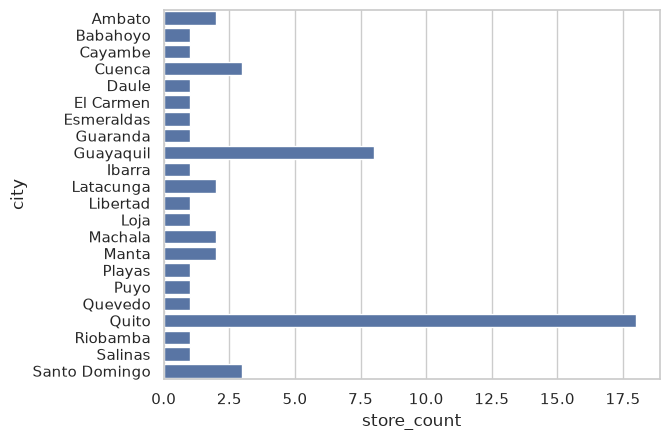

In [ ]:
num_stores_per_city = (
    df.groupby(["city"])["store_nbr"].count().reset_index(name="store_count")
)
sns.barplot(
    num_stores_per_city,
    y=num_stores_per_city["city"],
    x=num_stores_per_state["store_count"],
)

# Items data (items.csv)

In [ ]:
df = pd.read_parquet(
    "../data/favorita-grocery-sales-forecasting/cleaned/items_clean.parquet"
)
summary_df = summarize_dataframe(df, "Items Data")
summary_df

=== Stores Data Overview ===
Shape: 4,100 rows × 4 columns


,dtype,non_null_count,null_count,null_pct,nunique,min,max
item_nbr,int64,4100,0,0.0,4100,96995,2134244
family,str,4100,0,0.0,33,AUTOMOTIVE,SEAFOOD
class,int64,4100,0,0.0,337,1002,7780
perishable,int64,4100,0,0.0,2,0,1


Count of different items in each family

<Axes: xlabel='item_count', ylabel='family'>

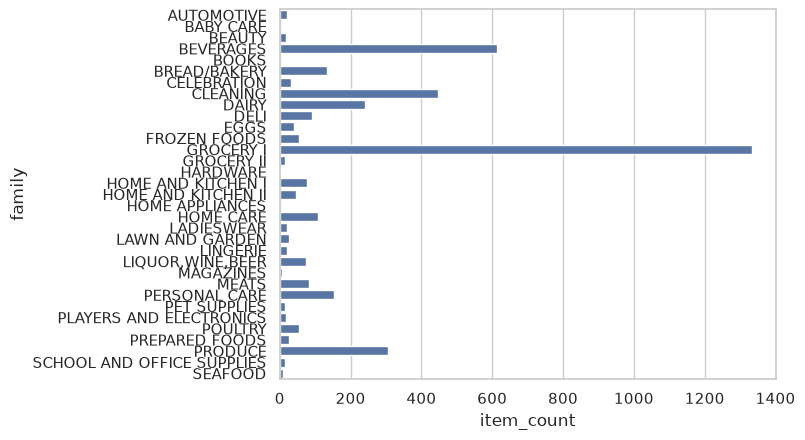

In [ ]:
num_items_per_family = (
    df.groupby(["family"])["item_nbr"].count().reset_index(name="item_count")
)
sns.barplot(
    num_items_per_family,
    y=num_items_per_family["family"],
    x=num_items_per_family["item_count"],
)

No . of unique different classes in each family

<Axes: xlabel='unique_classes', ylabel='family'>

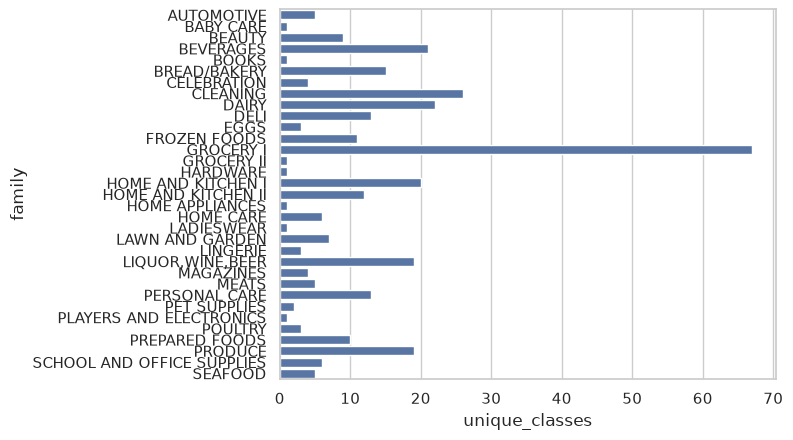

In [ ]:
df_class_family = (
    df.groupby(["family"])["class"].nunique().reset_index(name="unique_classes")
)
sns.barplot(
    df_class_family, y=df_class_family["family"], x=df_class_family["unique_classes"]
)

# Oil price data (oil.csv)

In [ ]:
df = pd.read_parquet(
    "../data/favorita-grocery-sales-forecasting/cleaned/oil_clean.parquet"
)
summary_df = summarize_dataframe(df, "Oil Price Data")
summary_df

=== Oil Price Data Overview ===
Shape: 1,218 rows × 2 columns


,dtype,non_null_count,null_count,null_pct,nunique,min,max
date,datetime64[us],1218,0,0.00,1218,2013-01-01 00:00:00,2017-08-31 00:00:00
dcoilwtico,float64,1175,43,3.53,998,26.19,110.62


In [ ]:
def plot_oil_price(oil_df, start_date="2013-01-01", end_date="2017-08-31"):
    """
    Plots daily oil prices (dcoilwtico) over time for a specified date range.
    """
    # 1. Filter data by date range
    mask = (oil_df["date"] >= start_date) & (oil_df["date"] <= end_date)
    sub_df = oil_df[mask].sort_values("date")

    # 2. Plot line chart
    plt.figure(figsize=(14, 5))
    sns.lineplot(data=sub_df, x="date", y="dcoilwtico", color="#e76f51", linewidth=1.8)

    plt.title(
        f"WTI Crude Oil Price Over Time ({start_date} to {end_date})", fontsize=14
    )
    plt.xlabel("Date", fontsize=12)
    plt.ylabel("Oil Price ($ USD / Barrel)", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

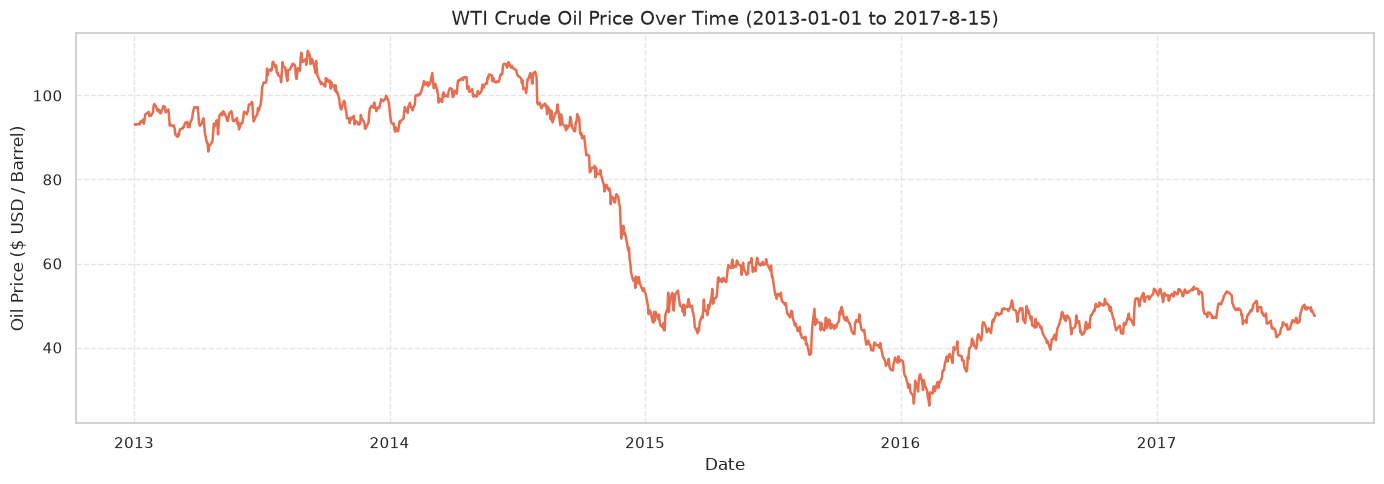

In [ ]:
plot_oil_price(df, start_date="2013-01-01", end_date="2017-8-15")

# Holiday data hilidays_events.csv

In [ ]:
df = pd.read_parquet(
    "../data/favorita-grocery-sales-forecasting/cleaned/holidays_events_clean.parquet"
)
summary_df = summarize_dataframe(df, "Holiday/Event Data")
summary_df

=== Holiday/Event Data Overview ===
Shape: 350 rows × 6 columns


,dtype,non_null_count,null_count,null_pct,nunique,min,max
date,datetime64[us],350,0,0.0,312,2012-03-02 00:00:00,2017-12-26 00:00:00
type,str,350,0,0.0,6,Additional,Work Day
locale,str,350,0,0.0,3,Local,Regional
locale_name,str,350,0,0.0,24,Ambato,Santo Domingo de los Tsachilas
description,str,350,0,0.0,103,Batalla de Pichincha,Viernes Santo
transferred,bool,350,0,0.0,2,False,True


In [ ]:
repeated_events = df[df.duplicated(subset=["date"], keep=False)].sort_values("date")
# Display the rows
repeated_events

,date,type,locale,locale_name,description,transferred
7,2012-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura,False
8,2012-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga,False
9,2012-06-25,Holiday,Local,Machala,Fundacion de Machala,False
10,2012-07-03,Holiday,Local,Santo Domingo,Fundacion de Santo Domingo,False
11,2012-07-03,Holiday,Local,El Carmen,Cantonizacion de El Carmen,False
...,...,...,...,...,...,...
319,2017-07-03,Holiday,Local,Santo Domingo,Fundacion de Santo Domingo,False
341,2017-12-08,Holiday,Local,Loja,Fundacion de Loja,False
342,2017-12-08,Transfer,Local,Quito,Traslado Fundacion de Quito,False
344,2017-12-22,Holiday,Local,Salinas,Cantonizacion de Salinas,False


In [ ]:
df.groupby(["type"])["date"].count()

type
Additional     51
Bridge          5
Event          56
Holiday       221
Transfer       12
Work Day        5
Name: date, dtype: int64

In [ ]:
df.groupby(["locale"])["date"].count()

locale
Local       152
National    174
Regional     24
Name: date, dtype: int64

In [ ]:
df.groupby(["locale", "transferred"])["date"].count()

locale    transferred
Local     False          148
          True             4
National  False          166
          True             8
Regional  False           24
Name: date, dtype: int64

In [2]:
df = pd.read_parquet(
    "../data/favorita-grocery-sales-forecasting/cleaned/test_clean.parquet"
)

In [6]:
summary_df = summarize_dataframe(df, "Training Data")
summary_df

=== Training Data Overview ===
Shape: 3,370,464 rows × 5 columns


,dtype,non_null_count,null_count,null_pct,nunique,min,max
id,int64,3370464,0,0.0,3370464,125497040,128867503
date,datetime64[us],3370464,0,0.0,16,2017-08-16 00:00:00,2017-08-31 00:00:00
store_nbr,int64,3370464,0,0.0,54,1,54
item_nbr,int64,3370464,0,0.0,3901,96995,2134244
onpromotion,bool,3370464,0,0.0,2,False,True
